In [51]:
import sys
from pathlib import Path
print(sys.executable)

# math imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score,f1_score,roc_curve, roc_auc_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from itertools import cycle

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree  

from sklearn.ensemble import RandomForestClassifier

/Users/codingfox/Documents/heart_machine_learning/myenv/bin/python


In [36]:
# load stuff and print
matches =  list(Path.cwd().rglob("processed_cleveland.csv"))

# print(matches)

heart_data = matches[0]
df = pd.read_csv(heart_data)
#print(df)

features = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak']
X = df[features]
y = df['num']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Logistic Regression

Accuracy: 0.5409836065573771
Precision: [0.61702128 0.66666667 0.         0.18181818 0.        ]
Recall: [1.         0.16666667 0.         0.28571429 0.        ]
ROC AUC Score: 0.7921465250746869


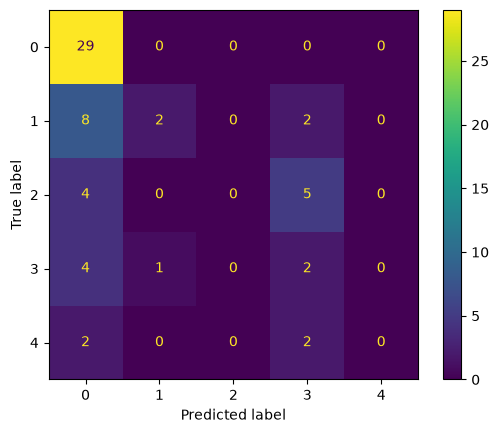

In [46]:
model = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(solver='liblinear', l1_ratio=1, C=0.1))
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, average=None, zero_division=0)
recall = recall_score(y_test, predictions, average=None)
print("Accuracy:" , accuracy)
print("Precision:", precision)
print("Recall:", recall)

# roc auc
y_score = model.predict_proba(X)
roc_auc = roc_auc_score(y, y_score, multi_class='ovr')
print(f"ROC AUC Score:", roc_auc)

# Create and Display Confusion Matrix
cm = confusion_matrix(y_test, predictions)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_display.plot()
plt.show()

## Decision Tree

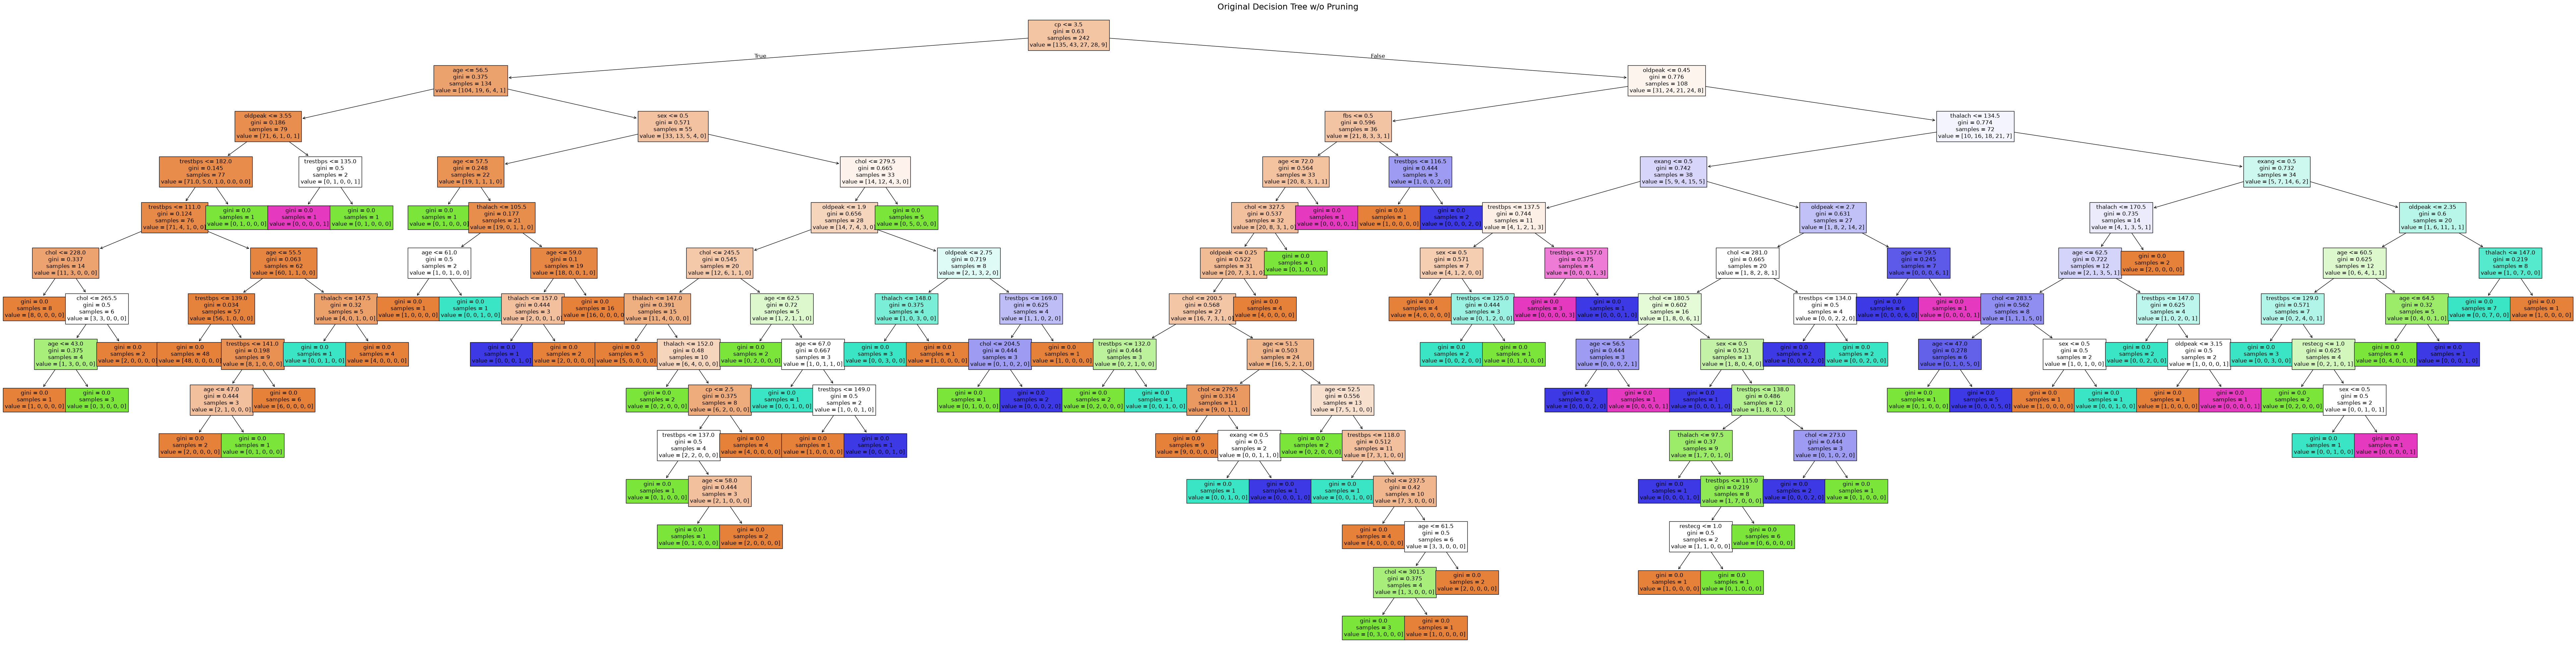

Accuracy w/o Pruning:  0.5081967213114754


In [52]:
model = DecisionTreeClassifier(criterion="gini")
model.fit(X_train, y_train)

plt.figure(figsize=(100,25))
plot_tree(
    model, 
    feature_names=features,
    filled=True,
    fontsize=12
    )
plt.title("Original Decision Tree w/o Pruning", fontsize = 18)
plt.show()

original_accuracy = model.score(X_test, y_test)
print("Accuracy w/o Pruning: " , original_accuracy)

In [60]:
from sklearn.model_selection import GridSearchCV

parameters = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter': ['best', 'random'],
    'max_depth': [1, 2, 3, 4, 5],
    'max_features': ['sqrt', 'log2']
}

tree = DecisionTreeClassifier()
cv = GridSearchCV(tree, param_grid=parameters, cv=5)
cv.fit(X_train, y_train)

path = model.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas

pruned_models = []

for alpha in ccp_alphas:
    pruned_model = DecisionTreeClassifier(
        criterion="gini",
        ccp_alpha=alpha
    )
    pruned_model.fit(X_train, y_train)
    pruned_models.append(pruned_model)

print("Best Accuracy:", cv.score(X_test, y_test))
print("Best Parameters:", cv.best_params_)

best_accuracy = 0
best_pruned_model = None

for m in pruned_models:
    acc = m.score(X_test, y_test)
    if acc > best_accuracy:
        best_accuracy = acc
        best_pruned_model = m

print("Accuracy after pruning:", best_accuracy)

'''
plt.figure(figsize=(100,25))
tree.plot_tree(
    model, 
    feature_names=features,
    filled=True,
    fontsize=12
    )
plt.title("Original Decision Tree w/o Pruning", fontsize = 18)
plt.show()

original_accuracy = model.score(X_test, y_test)
print("Accuracy w/o Pruning: " , original_accuracy)'''

Best Accuracy: 0.4918032786885246
Best Parameters: {'criterion': 'log_loss', 'max_depth': 4, 'max_features': 'log2', 'splitter': 'random'}
Accuracy after pruning: 0.5737704918032787


'\nplt.figure(figsize=(100,25))\ntree.plot_tree(\n    model, \n    feature_names=features,\n    filled=True,\n    fontsize=12\n    )\nplt.title("Original Decision Tree w/o Pruning", fontsize = 18)\nplt.show()\n\noriginal_accuracy = model.score(X_test, y_test)\nprint("Accuracy w/o Pruning: " , original_accuracy)'

## Random Forest

In [ ]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

